# 01 正弦波をローパスフィルタに通す(試作)

Arduino UNO R4 を信号発生器とオシロにして、Mimic を **1 次のローパスフィルタ(LPF)** にします。
正弦波を入れて、入力(CH1)と出力(CH2)をグラフで比べます。

> 試作のノートブックです。測定器(MimicLab)と Python のライブラリ(mimiclab)の動作確認を兼ねています。

## 準備

- [`../README.md`](../README.md) の結線をして、`firmware/MimicLab/MimicLab.ino` を UNO R4 に書き込んでおきます。
- このノートブックは `lectures` のフォルダで作った環境(`uv sync`)で開きます。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

`mimic=` のあとに Mimic のファームのビルド日が出ていれば、Mimic ともつながっています(`none` なら結線を確かめて `lab.mimic.begin()`)。

## 信号発生器:100 Hz の正弦波

振幅(ピーク)1 V の正弦波を出します。中心の電圧は**オフセット**(offset)と呼び、ここでは 2.5 V です(市販の信号発生器のつまみと同じ名前です)。

Mimic は 2.5 V を**信号の基準**(Vref、信号のグランドの代わり)として扱い、入力の Vref からのずれを信号として処理します。信号発生器のオフセットを Mimic の Vref に合わせておくのはこのためです。

In [2]:
lab.fg.sine(100, 1.0)  # 100 Hz, 1 V peak, around 2.5 V

{'wave': 'sine', 'freq': 100.0, 'amp': 1.0, 'offset': 2.5}

## Mimic:1 次のローパスフィルタ

カットオフ周波数 $f_c$ を 100 Hz にします。抵抗とコンデンサ 1 個ずつの RC フィルタと同じ働きです。

$f = f_c$ の正弦波を入れると、出力の振幅は入力の $1/\sqrt{2} \approx 0.707$ 倍になり、位相は 45° 遅れるはずです。

In [3]:
lab.mimic.filter1st_lpf(100)  # fc = 100 Hz

## 入力と出力を取り込む

20 kHz で 2000 点(0.1 秒、100 Hz なら 10 周期)取り込みます。取り込みは信号発生器の位相 0 から始まるので、何度取り込んでも同じところから始まります。

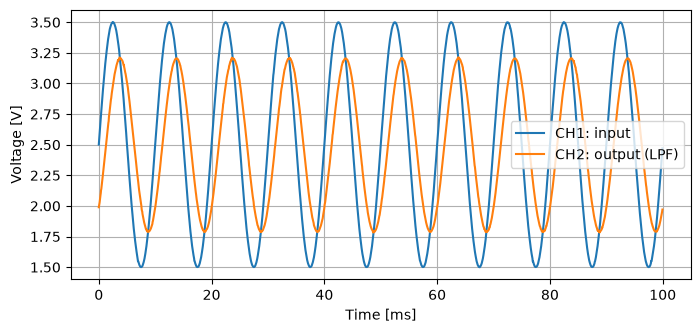

In [4]:
t, ch1, ch2 = lab.scope.capture(2000)  # 2000 points at 20 kHz

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (LPF)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## 振幅の比と位相のずれを求める

周波数がわかっている正弦波なので、$a \sin(2\pi f t) + b \cos(2\pi f t) + c$ を最小二乗法で当てはめて、振幅と位相を求めます。

In [5]:
def fit_sine(t, v, freq):
    """Amplitude [V], phase [deg] and offset [V] of a sine of a known frequency."""
    w = 2 * np.pi * freq
    A = np.column_stack([np.sin(w * t), np.cos(w * t), np.ones_like(t)])
    a, b, c = np.linalg.lstsq(A, v, rcond=None)[0]
    return np.hypot(a, b), np.degrees(np.arctan2(b, a)), c

amp_in, ph_in, dc_in = fit_sine(t, ch1, 100)
amp_out, ph_out, dc_out = fit_sine(t, ch2, 100)
print(f"input : {amp_in:.3f} V, offset {dc_in:.3f} V")
print(f"output: {amp_out:.3f} V, offset {dc_out:.3f} V")
print(f"gain  : {amp_out / amp_in:.3f}   (theory 0.707)")
print(f"phase : {ph_out - ph_in:.1f} deg (theory -45)")

input : 1.000 V, offset 2.500 V
output: 0.707 V, offset 2.497 V
gain  : 0.707   (theory 0.707)
phase : -46.2 deg (theory -45)


振幅の比はほぼ理論どおりになります。位相は理論より 1° ほど多く遅れます。Mimic はデジタルで計算するので、入力から出力までに数十 µs の遅れがあるためです(100 Hz では 10 µs が 0.36°)。また、この測定器は CH1 と CH2 を数 µs ずらして読んでいます。

## カットオフ周波数を変えてみる

$f_c$ を変えて、出力の振幅と遅れがどう変わるかを見ます。$f_c$ が信号より低いほど、出力は小さく、遅れは大きくなります(90° に近づく)。

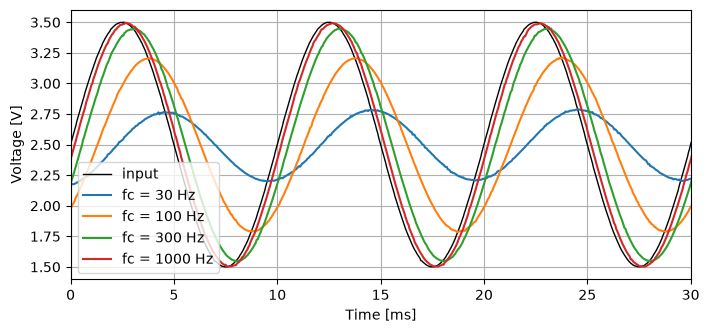

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, "k", lw=1, label="input")
for fc in [30, 100, 300, 1000]:
    lab.mimic.filter1st_lpf(fc)
    t, ch1, ch2 = lab.scope.capture(2000)
    ax.plot(t * 1e3, ch2, label=f"fc = {fc} Hz")
ax.set_xlim(0, 30)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## おわりに

Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [7]:
lab.mimic.bypass()
lab.close()